Instagram Personal Data Report

Name: Daniel Hanson
Date: September 23, 2026

Source and Structure of the Data

The liked_posts.json file has information about tracked posts that I have liked. The JSON file contains timestamps, media information, labels, and account information. Some of the information is inside lists and dictionaries, so that means the data needs to be cleaned before it can be easily analyzed.

The data may be reliable because Instagram automatically records activity with my account. However, the data may also have limitations because it has no way of tracking old or Deleted content.

In [45]:
import json
import pandas as pd
import matplotlib.pyplot as plt

In [47]:
with open('liked_posts.json', 'r') as file:
    DanLikedPost = json.load(file)

Wrangling Likes Data

The original likes data contains information that is difficult to analyze directly. To make the data manageable I loop through each data entry and create a new row for each like. I convert the original timestamp into separate Date and Time variables.

In [48]:
tidy_rows = []

for entry in DanLikedPost:

    row = {}

    datetime = pd.to_datetime(entry['timestamp'], unit='s')

    row['Date'] = datetime.date()
    row['Time'] = datetime.time()

    for item in entry['label_values']:

        if 'label' in item:
            row[item['label']] = item['value']

        elif item.get('title') == 'Owner':
            owner_fields = item['dict'][0]['dict']

            for owner_item in owner_fields:
                row['Owner ' + owner_item['label']] = owner_item['value']

    tidy_rows.append(row)

tidy_rows[0]

{'Date': datetime.date(2026, 9, 5),
 'Time': datetime.time(3, 12),
 'URL': 'https://www.instagram.com/reel/Dc2P9AMKc-k/',
 'Caption': 'Is it better with or without?\n#pedal #with #without #vs #piano',
 'Title': '',
 'Owner URL': '',
 'Owner Name': 'Klavirad',
 'Owner Username': 'unaplayspiano'}

In [49]:
likes_df = pd.DataFrame(tidy_rows)

likes_df.head(10)

,Date,Time,URL,Caption,Title,Owner URL,Owner Name,Owner Username
0,2026-09-05,03:12:00,https://www.instagram.com/reel/Dc2P9AMKc-k/,Is it better with or without?\n#pedal #with #w...,,,Klavirad,unaplayspiano
1,2026-08-19,04:27:22,https://www.instagram.com/p/DcMd5JWFEUc0utouOH...,some favorites from florida ð,,http://vsco.co/analeise-artino,analeise artino,analeise.artino
2,2026-08-15,15:02:10,https://www.instagram.com/p/DcCcIJPFVRe/,ðð,,,Joshua Van Bawi Thawng ð²ð²,thefearlessmma1
3,2026-08-08,14:12:08,https://www.instagram.com/p/DbyDC-olTC5/,VA,,,Maggie Hanson,maggiehanson_02
4,2026-07-07,04:41:39,https://www.instagram.com/p/DaN1lgtAYFo/,Kick off the FIFA World Cup 2026â¢ with our l...,,http://spr.ly/UGCPolicy_ENG,Don Julio Tequila,donjuliotequila
5,2026-06-22,01:16:56,https://www.instagram.com/p/DZ3o1ptDBnORExJO5C...,Lil bit of life latelyððï¸ð¹ #obx #year5,,,Maeson Atha,maeson_atha
6,2026-06-22,00:50:50,https://www.instagram.com/p/DZ2qEmoFnTMNd-lH7J...,ðï¸ð³,,,Jack,jackzagata
7,2026-06-21,00:05:27,https://www.instagram.com/p/DZ0326tEbUk80sQLmD...,together again!,,http://vsco.co/analeise-artino,analeise artino,analeise.artino
8,2026-06-19,06:43:02,https://www.instagram.com/reel/DYfov-lCCsA/,@play.cashy One of the coldest quotes from Jon...,,,,ironfisthq
9,2026-06-18,03:14:59,https://www.instagram.com/p/DZqAA3dGtEv/,Who else sees itð­\n\nZac Efronâs look in ...,,https://bit.ly/3TRyERo,No Memes,i_have_no_memes96_v2


In [50]:
likes_df.columns

Index(['Date', 'Time', 'URL', 'Caption', 'Title', 'Owner URL', 'Owner Name',
       'Owner Username'],
      dtype='str')

In [51]:
likes_by_account = likes_df.groupby('Owner Username')['Date'].count()

likes_by_account

Owner Username
70_riviera          1
_aidanjack2027      1
_bballdaily         1
_generalmills__     1
_girltechdecker_    1
                   ..
young_miyagi        1
zacharygottlieb2    1
zachsamarin         1
zack_whetzel        1
zuccccccccccc       1
Name: Date, Length: 205, dtype: int64

In [66]:
likes_by_account = likes_by_account.sort_values(ascending=False)

likes_by_account.iloc[1:]

Owner Username
analeise.artino    20
crssd              19
kingjames          15
bigdawg_h00per     14
free.drinks         7
                   ..
louisbearzi         1
thefearlessmma1     1
thecheckdown        1
stormboen           1
zuccccccccccc       1
Name: Date, Length: 204, dtype: int64

Likes Analysis

I grouped the likes data by Instagram account and counted the number of likes connected with each account. This allows me to determine which accounts appear most frequently in my liked posts history. Sorting the results from highest to lowest makes it easier to find the accounts that received the most likes.

Hypothesis

I hypothesize that I save more Instagram posts during the evening than during the morning.

The theoretical reasoning behind this hypothesis is that I am more likely to browse Instagram during my free time later in the day. Because I spend more time using Instagram during the evening, I expect that I would also save more posts during this period.I can investigate this hypothesis by sorting the times associated with my saved posts. 

Saved Posts Data

I selected the saved_post.json file to investigate my hypothesis. I expect this file to contain records of posts that I have saved on Instagram, including timestamps and information about the posts.

The timestamp information is particularly useful because it allows me to determine what time of day each post was saved. I can use this information to compare my activity at different times of the day.

In [54]:
with open('saved_posts.json', 'r') as file:
    DanSavedPost = json.load(file)

Wrangling the Saved Posts Data

 I use the same general wrangling process that I used for the likes data. Each saved post becomes one row in the dataset and any other information stored inside the JSON data set is separated into individual variables. I also convert the original timestamp into separate Date and Time columns.

In [55]:
saved_tidy_rows = []

for entry in DanSavedPost:

    row = {}

    datetime = pd.to_datetime(entry['timestamp'], unit='s')

    row['Date'] = datetime.date()
    row['Time'] = datetime.time()

    for item in entry['label_values']:

        if 'label' in item:
            row[item['label']] = item['value']

        elif item.get('title') == 'Owner':
            owner_fields = item['dict'][0]['dict']

            for owner_item in owner_fields:
                row['Owner ' + owner_item['label']] = owner_item['value']

    saved_tidy_rows.append(row)

saved_tidy_rows[0]

{'Date': datetime.date(2026, 9, 9),
 'Time': datetime.time(18, 7, 32),
 'URL': 'https://www.instagram.com/reel/DafpGDZx3Lf/',
 'Caption': 'We found love in a hopeless place (a comedy club)\n.\n.\n.\n#comedy #standupcomedy #femalecomedian #crowdwork #heckler',
 'Title': '',
 'Owner URL': 'https://linktr.ee/Rebeccareingold',
 'Owner Name': 'Rebecca Reingold',
 'Owner Username': 'rebeccareingold'}

In [56]:
saved_df = pd.DataFrame(saved_tidy_rows)

saved_df.head(10)

,Date,Time,URL,Caption,Title,Owner URL,Owner Name,Owner Username
0,2026-09-09,18:07:32,https://www.instagram.com/reel/DafpGDZx3Lf/,We found love in a hopeless place (a comedy cl...,,https://linktr.ee/Rebeccareingold,Rebecca Reingold,rebeccareingold
1,2026-09-09,14:09:53,https://www.instagram.com/reel/DaFMhAaqs5v/,Anime info â¬ï¸\n\nâ¢ Anime : The Case Stud...,,,á´á´É´á´Êá´Ê,monarchnews0
2,2026-09-08,14:41:31,https://www.instagram.com/reel/DdBEKQSRJxR/,The Fated Magical Princess: Who Made Me a Prin...,,https://x.com/youknowmearound?s=11,Natsuki,youknowmearound
3,2026-09-05,23:15:27,https://www.instagram.com/reel/Dc43i9QTerx/,The Insipid Princeâs Furtive Grab for The Th...,,https://www.instagram.com/darling__zero__two__...,DÃ¤mÃ¬Ã¥Ã± ÃgÃ¬tÃ¸k SÃ¤Ã±gmÃ¥,darling__zero__two____
4,2026-09-05,23:07:35,https://www.instagram.com/reel/DV1lZohDghS/,The new hero stood no chance ð®âð¨\n\nð...,,https://otakuspecter.beehiiv.com/,OtakuSpecter | Anime Content | US,otakuspecter
5,2026-09-05,23:01:39,https://www.instagram.com/reel/Dc6Kb8-y1PK/,Anime details are here â\n\nAnime: Megami no...,,,@ANIME | CONTENT,animex___editz444
6,2026-09-05,22:43:36,https://www.instagram.com/reel/DalE-sIPWMV/,ð¥ The MC is a boy BTW. \nAnime Info â¬ï¸ ...,,,ANIMEGENETIX,animegenetix
7,2026-09-05,22:28:55,https://www.instagram.com/reel/Dc6V8wWtm-O/,"No hands, no feet, no problem ð ââï¸ð...",,https://roosfosterfriends.myshopify.com,Rooâs Foster Friends | Kittens | Cats | Resc...,roos.fosterfriends
8,2026-09-04,17:23:29,https://www.instagram.com/reel/Dc2xRNRvZSE/,ããããè¿½ãããã£ããç¹°ãåºãã...,,,ê§à¼â¬Zalim..â¤ï¸.. Queenâ¬à¼ê§,anime_world_8790
9,2026-09-03,19:31:39,https://www.instagram.com/reel/DczFP1lBhLW/,Anime Iâm HYPED for based on the artðï¸ð...,,https://linktr.ee/mbsagard,Marybelle Sagard,marybellesagard


In [57]:
saved_df.columns

Index(['Date', 'Time', 'URL', 'Caption', 'Title', 'Owner URL', 'Owner Name',
       'Owner Username'],
      dtype='str')

In [60]:
saved_by_hour = saved_df.groupby('Hour')['Date'].count()

saved_by_hour

Hour
0      86
1     100
2      70
3      71
4      49
5      18
6       8
7       7
9       9
10     20
11     57
12     78
13    132
14    162
15    166
16    139
17    121
18    141
19    185
20    118
21     81
22    129
23    101
Name: Date, dtype: int64

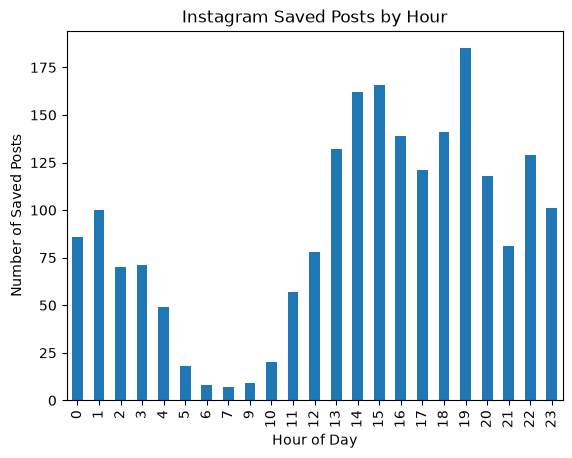

In [61]:
saved_by_hour.plot(kind='bar')

plt.title('Instagram Saved Posts by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Saved Posts')

plt.show()

Conclusion

The analysis showed that the number of Instagram posts I saved varied across different hours of the day. The hour with the highest number of saved posts was at the end or evening of the day. Which agrees with my hypothesis.